# Quadratic discriminant analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse
from scipy.stats import multivariate_normal
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

Linear discriminant analysis (LDA) assumes that the classes are Gaussian with the same covariance matrix, and its decision boundary is a line. Quadratic discriminant analysis (QDA) estimates one covariance matrix for each class, and its boundary is a quadratic curve.

We simulate two Gaussian classes with different covariance matrices: the first one is more spread horizontally, the second one vertically.

In [2]:
mu1 = [10, 5]
V1  = [[6, 0], [0, 2.5]]
n1 = 50
mu2 = [10, 10]
V2  = [[2.5, 0], [0, 6]]
n2 = 50

rng = np.random.default_rng(159)
X1 = rng.multivariate_normal(mean=mu1, cov=V1, size=n1)
X2 = rng.multivariate_normal(mean=mu2, cov=V2, size=n2)

X1          = pd.DataFrame(X1, columns=['x', 'y'])
X1['class'] = 1

X2          = pd.DataFrame(X2, columns=['x', 'y'])
X2['class'] = -1

dat = pd.concat([X1, X2], ignore_index=True)

In [3]:
class_colors = {1: '#0072B2', -1: '#E69F00'}
class_markers = {1: 'o', -1: 's'}

def plot_points(ax):
    for c in [1, -1]:
        rows = dat[dat['class'] == c]
        ax.plot(rows['x'], rows['y'], class_markers[c], color=class_colors[c], markersize=8, markeredgecolor='white',
                markeredgewidth=0.6, label=f'Class {c}')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_aspect('equal')

def plot_ellipse(ax, mean, cov, color):
    # Ellipse with 95% of the probability of a Gaussian distribution
    values, vectors = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vectors[1, -1], vectors[0, -1]))
    width, height = 2*np.sqrt(5.991*values[::-1])
    ax.add_patch(Ellipse(mean, width, height, angle=angle, facecolor='none', edgecolor=color, lw=1.5, ls='--'))

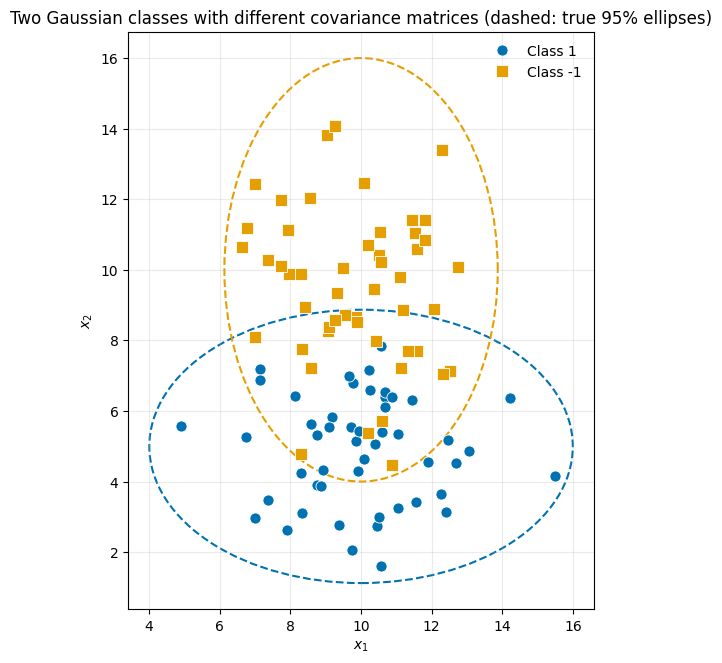

In [4]:
fig, ax = plt.subplots(figsize=(10, 7.5))
plot_points(ax)
plot_ellipse(ax, mu1, np.array(V1), class_colors[1])
plot_ellipse(ax, mu2, np.array(V2), class_colors[-1])
ax.set_title('Two Gaussian classes with different covariance matrices (dashed: true 95% ellipses)')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, alpha=0.25)

## LDA and QDA

In [5]:
lda = LinearDiscriminantAnalysis(store_covariance=True)
lda.fit(dat[['x', 'y']], dat['class'])

qda = QuadraticDiscriminantAnalysis(store_covariance=True)
qda.fit(dat[['x', 'y']], dat['class'])

b0 = lda.intercept_[0]
w1 = lda.coef_[0][0]
w2 = lda.coef_[0][1]

print(f'LDA: b0 = {b0:.4f}, w1 = {w1:.4f}, w2 = {w2:.4f}')

LDA: b0 = 10.1668, w1 = -0.0699, w2 = -1.3132


The boundary of LDA is the line $b_0 + w_1x_1 + w_2x_2 = 0$. For QDA we evaluate the probability of the class 1 on a grid, the boundary is the curve where it is 0.5. Since we simulated the data we can also draw the best possible boundary (the Bayes rule), which uses the true means and covariance matrices.

In [6]:
xminmax = np.array([np.min(dat['x']), np.max(dat['x'])])
yminmax = np.array([np.min(dat['y']), np.max(dat['y'])])

xx, yy = np.meshgrid(np.linspace(xminmax[0]-1, xminmax[1]+1, 300), np.linspace(yminmax[0]-1, yminmax[1]+1, 300))
dat_grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=['x', 'y'])

Z_qda = qda.predict_proba(dat_grid)[:, 1].reshape(xx.shape)
Z_lda = lda.predict_proba(dat_grid)[:, 1].reshape(xx.shape)
ylda = -(b0+(xminmax+[-1,1])*w1)/w2

# Bayes rule: difference of the true log-densities (the classes have the same size)
Z_bayes = (multivariate_normal(mu1, V1).logpdf(dat_grid) - multivariate_normal(mu2, V2).logpdf(dat_grid)).reshape(xx.shape)

error_lda = 100*np.mean(lda.predict(dat[['x', 'y']]) != dat['class'])
error_qda = 100*np.mean(qda.predict(dat[['x', 'y']]) != dat['class'])
print(f'Apparent error of LDA: {error_lda:.0f}%')
print(f'Apparent error of QDA: {error_qda:.0f}%')

Apparent error of LDA: 7%
Apparent error of QDA: 7%


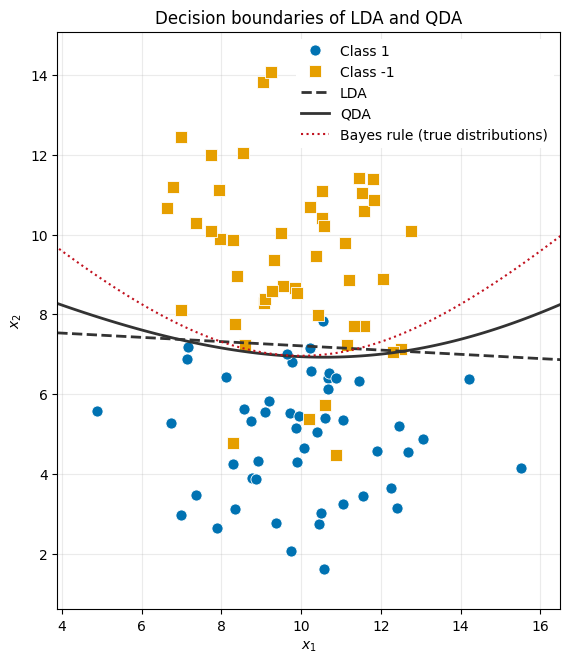

In [7]:
fig, ax = plt.subplots(figsize=(10, 7.5))
plot_points(ax)
ax.plot(xminmax+[-1,1], ylda, color='#333333', linestyle='--', lw=2)
ax.contour(xx, yy, Z_qda, [0.5], colors='#333333', linewidths=2)
ax.contour(xx, yy, Z_bayes, [0], colors='#c1121f', linewidths=1.5, linestyles=':')

handles, labels = ax.get_legend_handles_labels()
handles += [Line2D([], [], color='#333333', ls='--', lw=2), Line2D([], [], color='#333333', lw=2),
            Line2D([], [], color='#c1121f', ls=':', lw=1.5)]
labels += ['LDA', 'QDA', 'Bayes rule (true distributions)']
ax.set_ylim(yminmax[0]-1, yminmax[1]+1)
ax.set_xlim(xminmax[0]-1, xminmax[1]+1)
ax.set_title('Decision boundaries of LDA and QDA')
ax.legend(handles, labels, loc='upper right', framealpha=1, edgecolor='none')
ax.grid(True, alpha=0.25)

## Decision regions and estimated covariances

Each panel shows the region assigned to each class, the misclassified points (ringed) and the 95% ellipses of the estimated Gaussian distributions: one common shape for LDA, one shape for each class for QDA.

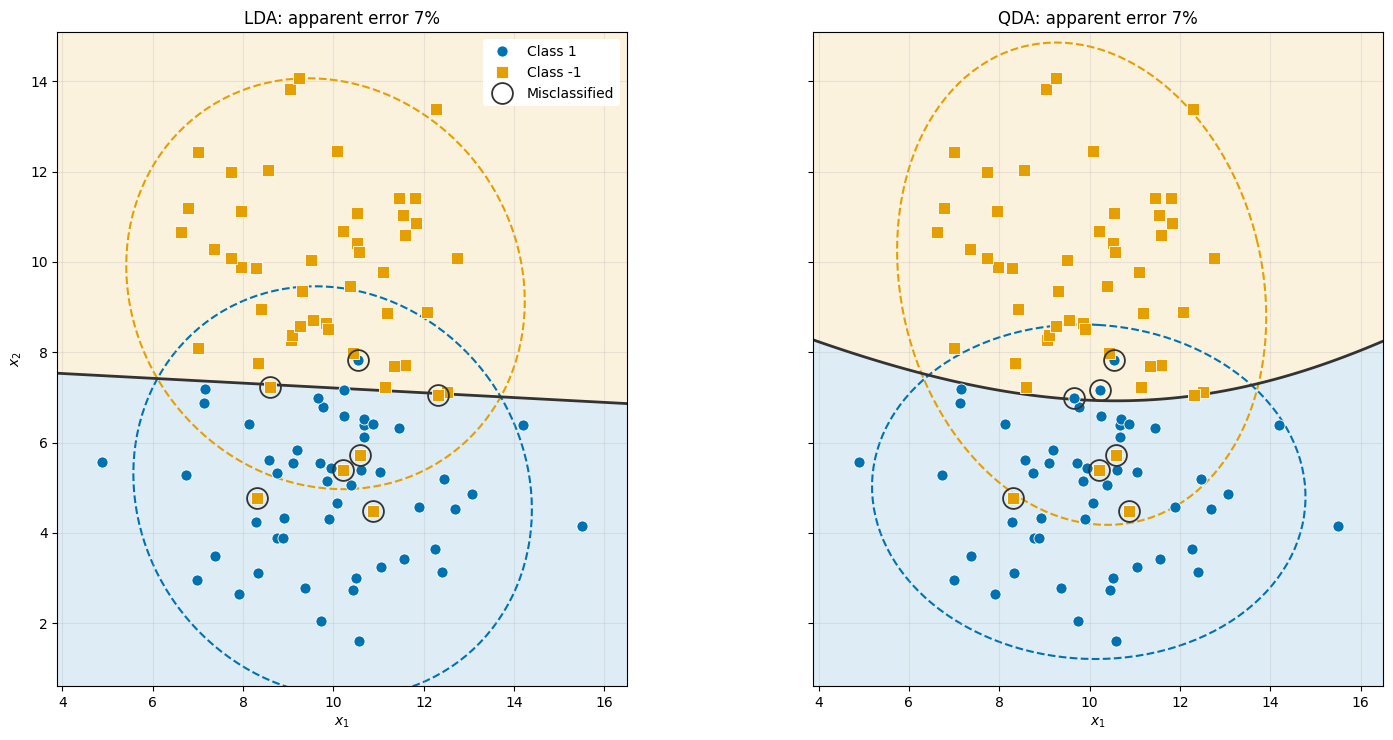

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), sharey=True)
models = [(axes[0], lda, Z_lda, 'LDA', error_lda), (axes[1], qda, Z_qda, 'QDA', error_qda)]
for ax, model, Z, name, error in models:
    ax.contourf(xx, yy, Z, levels=[0, 0.5, 1], colors=[class_colors[-1], class_colors[1]], alpha=0.13)
    ax.contour(xx, yy, Z, [0.5], colors='#333333', linewidths=2)
    plot_points(ax)

    wrong = model.predict(dat[['x', 'y']]) != dat['class']
    ax.plot(dat.loc[wrong, 'x'], dat.loc[wrong, 'y'], 'o', markersize=15, markerfacecolor='none',
            markeredgecolor='#333333', markeredgewidth=1.3, label='Misclassified')

    # Estimated distributions: classes_ is sorted, (-1, 1)
    for i, c in enumerate(model.classes_):
        cov = lda.covariance_ if name == 'LDA' else qda.covariance_[i]
        plot_ellipse(ax, model.means_[i], cov, class_colors[c])
    ax.set_xlim(xminmax[0]-1, xminmax[1]+1)
    ax.set_ylim(yminmax[0]-1, yminmax[1]+1)
    ax.set_title(f'{name}: apparent error {error:.0f}%')
    ax.grid(True, alpha=0.25)
axes[1].set_ylabel('')
axes[0].legend(loc='upper right', framealpha=1, edgecolor='none')
plt.tight_layout()